# Implement a text classification algorithm (e.g., Naive Bayes or SVM) to classify emails as spam or not spam.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
df = pd.read_csv("SpamAssasin.csv")
df = df[["subject", "body", "label"]].fillna("")
df["text"] = df["subject"] + " " + df["body"]
print(df.shape)
print(df["label"].value_counts())

(5809, 4)
label
0    4091
1    1718
Name: count, dtype: int64


In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " url ", text)    # replace links
    text = re.sub(r"\S+@\S+", " email ", text)          # replace email addresses
    text = re.sub(r"[^a-z\s]", " ", text)               # keep only letters
    return re.sub(r"\s+", " ", text).strip()


In [5]:
df["clean_text"] = df["text"].apply(clean_text)
print(df["clean_text"].head())

0    re new sequences window date wed aug from chri...
1    zzzzteana re alexander martin a posted tassos ...
2    zzzzteana moscow bomber man threatens explosio...
3    irr klez the virus that won t die klez the vir...
4    re zzzzteana nothing like mama used to make in...
Name: clean_text, dtype: object


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.2, random_state=42, stratify=df["label"])


In [7]:
vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)


===== Naive Bayes =====
Accuracy: 0.9673
              precision    recall  f1-score   support

    Not Spam       0.97      0.98      0.98       818
        Spam       0.96      0.93      0.94       344

    accuracy                           0.97      1162
   macro avg       0.96      0.96      0.96      1162
weighted avg       0.97      0.97      0.97      1162



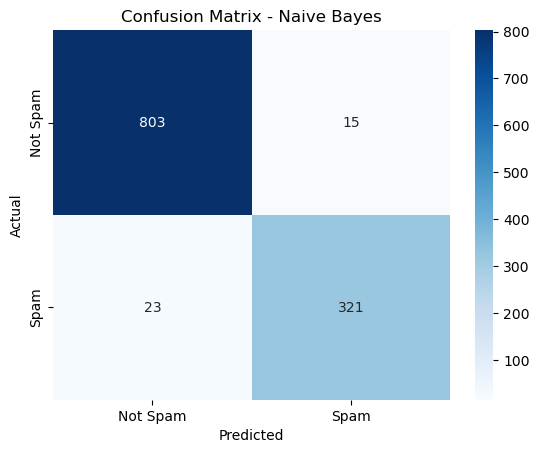


===== SVM =====
Accuracy: 0.9836
              precision    recall  f1-score   support

    Not Spam       0.99      0.99      0.99       818
        Spam       0.98      0.97      0.97       344

    accuracy                           0.98      1162
   macro avg       0.98      0.98      0.98      1162
weighted avg       0.98      0.98      0.98      1162



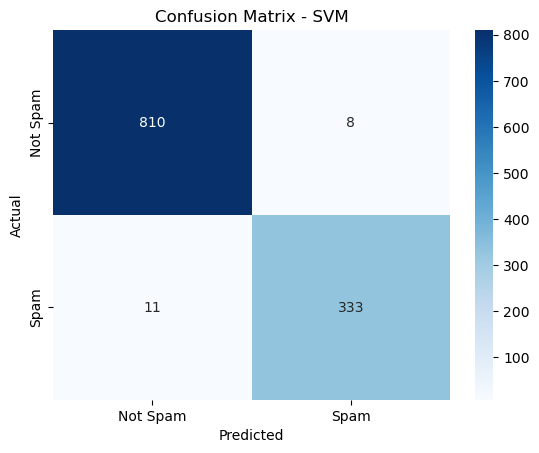

In [9]:
models = {
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC(),
}

for name, model in models.items():
    model.fit(X_train_vec, y_train)
    pred = model.predict(X_test_vec)
    print(f"\n===== {name} =====")
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print(classification_report(y_test, pred, target_names=["Not Spam", "Spam"]))

    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Not Spam", "Spam"], yticklabels=["Not Spam", "Spam"])
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.show()


Top spam words:
 mortgage                             3.946910
mailings                             3.315616
refinance                            3.066053
credit                               3.031667
toners                               2.976019
loan                                 2.970114
dqo                                  2.960168
deathtospamdeathtospamdeathtospam    2.932990
guaranteed                           2.906774
lenders                              2.884219
click                                2.873367
loans                                2.829858
viagra                               2.774184
insurance                            2.752146
yni                                  2.685628
dtype: float64


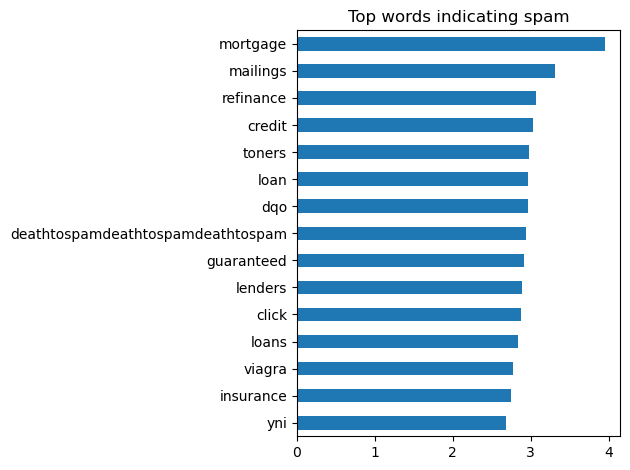

In [10]:
nb = models["Naive Bayes"]
words = vectorizer.get_feature_names_out()
spam_score = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
top_spam = pd.Series(spam_score, index=words).sort_values(ascending=False).head(15)
print("\nTop spam words:\n", top_spam)
top_spam.sort_values().plot(kind="barh", title="Top words indicating spam")
plt.tight_layout()
plt.show()

In [11]:
new_emails = [
    "Congratulations! You have won a free iPhone. Click here to claim your prize now",
    "Hi team, please find attached the minutes of today's project meeting",
]
new_vec = vectorizer.transform([clean_text(e) for e in new_emails])
for email, nb_pred, svm_pred in zip(new_emails, nb.predict(new_vec), models["SVM"].predict(new_vec)):
    print(f"\n{email}\n  Naive Bayes: {'Spam' if nb_pred else 'Not Spam'} | SVM: {'Spam' if svm_pred else 'Not Spam'}")


Congratulations! You have won a free iPhone. Click here to claim your prize now
  Naive Bayes: Spam | SVM: Spam

Hi team, please find attached the minutes of today's project meeting
  Naive Bayes: Not Spam | SVM: Not Spam
